# v0Engine Results and Analysis


In [28]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt




df = pd.read_csv("../benchmarks/data/v0_gpu.csv")
df.head()

,engine,trial,num_requests,prompt_tokens,output_tokens,total_tokens,latency_ms,throughput_tok_s,throughput_req_s,mean_ttft_ms,p50_ttft_ms,p95_ttft_ms,mean_tpot_ms,mean_queue_ms,mean_request_latency_ms,p95_request_latency_ms,peak_gpu_memory_mb
0,v0,1,1,16,32,32,78.497988,407.653761,12.739180,2.836998,2.836998,2.836998,2.438701,0.000611,78.436723,78.436723,508.281856
1,v0,2,1,16,32,32,79.167954,404.203954,12.631374,3.170683,3.170683,3.170683,2.449276,0.000531,79.098253,79.098253,508.281856
2,v0,3,1,16,32,32,78.580373,407.226369,12.725824,2.814696,2.814696,2.814696,2.441972,0.000411,78.515842,78.515842,508.281856
3,v0,1,1,32,32,32,77.348574,413.711570,12.928487,2.783458,2.783458,2.783458,2.403606,0.000330,77.295244,77.295244,508.331008
4,v0,2,1,32,32,32,77.844644,411.075167,12.846099,2.810068,2.810068,2.810068,2.418212,0.000361,77.774643,77.774643,508.331008


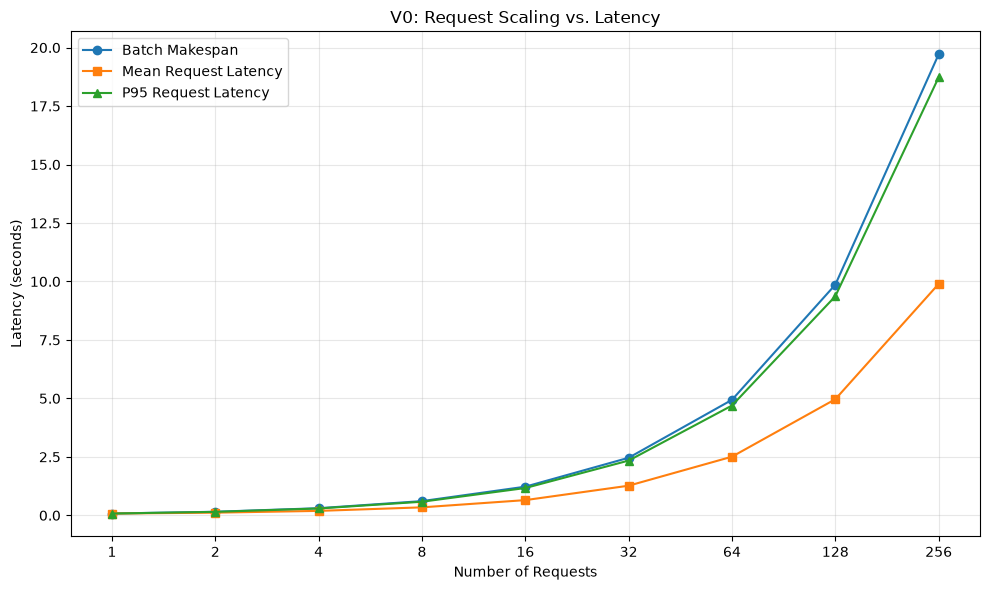

In [29]:
# Experiment 1: Request Scaling (P=32, O=32)
e1 = df[
    (df["prompt_tokens"] == 32) &
    (df["output_tokens"] == 32) &
    (df["num_requests"] <= 256)
]

# Median across 3 trials per configuration
e1 = e1.groupby("num_requests", as_index=False)[
    ["latency_ms", "mean_request_latency_ms", "p95_request_latency_ms"]
].median()

# Convert milliseconds to seconds
x = e1["num_requests"]

plt.figure(figsize=(10, 6))

plt.plot(x, e1["latency_ms"] / 1000,
         marker="o", label="Batch Makespan")

plt.plot(x, e1["mean_request_latency_ms"] / 1000,
         marker="s", label="Mean Request Latency")

plt.plot(x, e1["p95_request_latency_ms"] / 1000,
         marker="^", label="P95 Request Latency")

plt.xscale("log", base=2)
plt.xticks(x, labels=x)

plt.xlabel("Number of Requests")
plt.ylabel("Latency (seconds)")
plt.title("V0: Request Scaling vs. Latency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("v0_e1_latency.png", dpi=600)
plt.show()

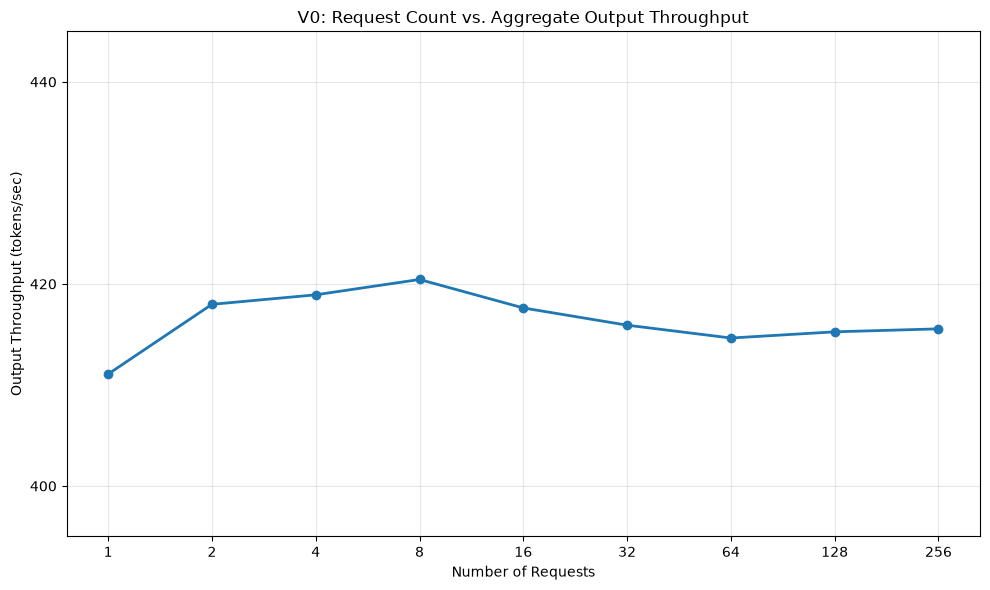

In [30]:
from matplotlib.ticker import MultipleLocator


# Experiment 1: Request Scaling - Aggregate Throughput
e1 = df[
    (df["prompt_tokens"] == 32) &
    (df["output_tokens"] == 32) &
    (df["num_requests"] <= 256)
]

# Median throughput across 3 trials
e1 = e1.groupby("num_requests", as_index=False)[
    "throughput_tok_s"
].median()

x = e1["num_requests"]

plt.figure(figsize=(10, 6))

plt.plot(
    x,
    e1["throughput_tok_s"],
    marker="o",
    linewidth=2,
    label="Output Throughput"
)

plt.xscale("log", base=2)
plt.xticks(x, labels=x)

plt.xlabel("Number of Requests")
plt.ylabel("Output Throughput (tokens/sec)")
plt.title("V0: Request Count vs. Aggregate Output Throughput")
plt.yticks([400, 420, 440])
plt.ylim(395, 445)
plt.yticks([400, 420, 440])
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("v0_e1_throughput.png", dpi=600)
plt.show()

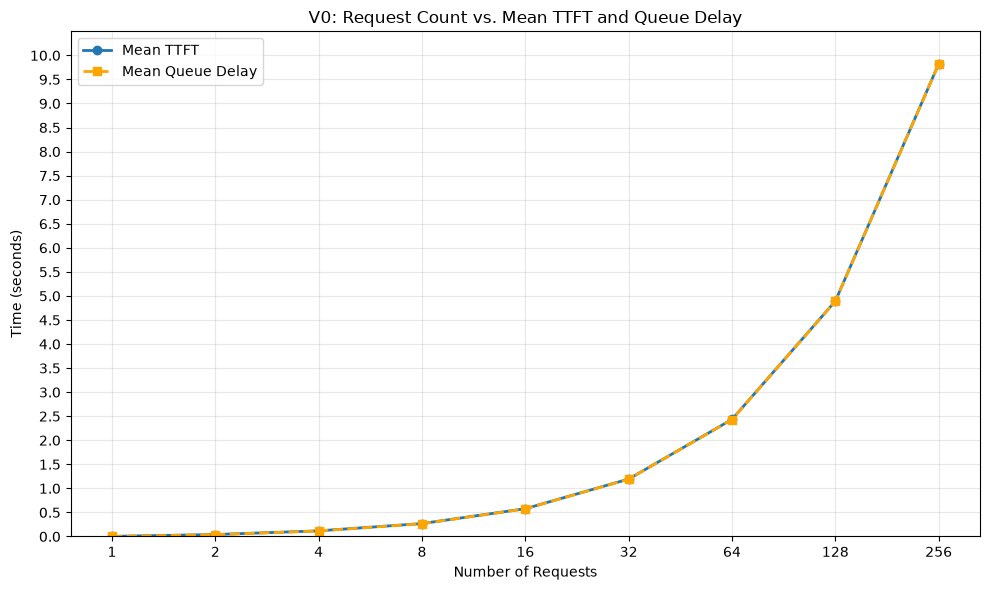

In [31]:
# Experiment 1: Request Scaling - TTFT and Queue Delay
e1 = df[
    (df["prompt_tokens"] == 32) &
    (df["output_tokens"] == 32) &
    (df["num_requests"] <= 256)
]

# Median across 3 trials
e1 = e1.groupby("num_requests", as_index=False)[
    ["mean_ttft_ms", "mean_queue_ms"]
].median()

x = e1["num_requests"]

plt.figure(figsize=(10, 6))

plt.plot(
    x,
    e1["mean_ttft_ms"] / 1000,
    marker="o",
    linewidth=2,
    label="Mean TTFT"
)

plt.plot(
    x,
    e1["mean_queue_ms"] / 1000,
    marker="s",
    linewidth=2,
    linestyle="--",
    color="orange",
    label="Mean Queue Delay"
)

plt.xscale("log", base=2)
plt.xticks(x, labels=x)

plt.xlabel("Number of Requests")
plt.ylabel("Time (seconds)")
plt.title("V0: Request Count vs. Mean TTFT and Queue Delay")
plt.yticks(np.arange(0, 10.5, 0.5))
plt.ylim(0, 10.5)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("v0_e1_ttft_queue.png", dpi=300)
plt.show()

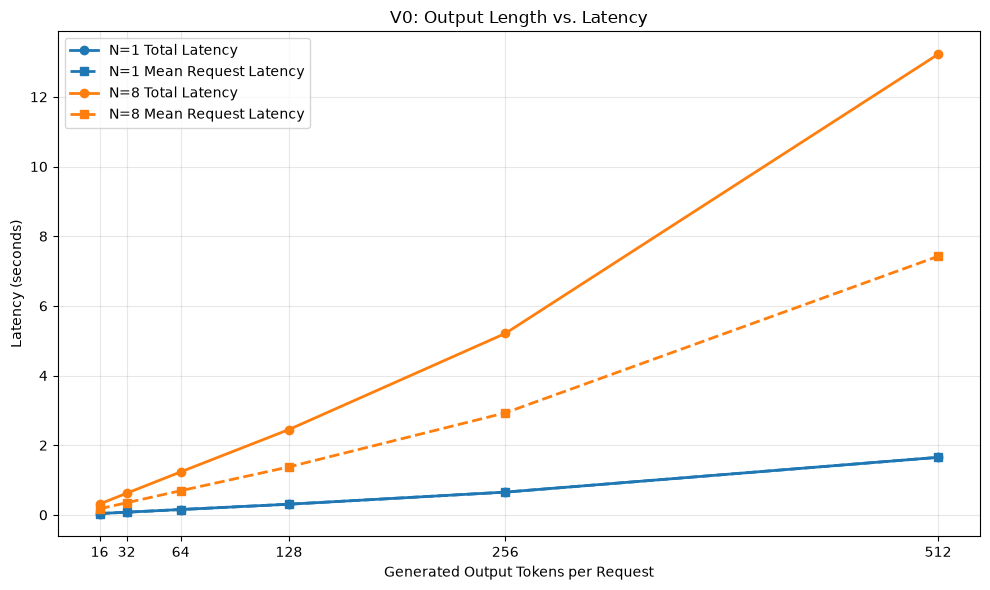

In [35]:
# Experiment 2: Output Scaling - Total and Mean Request Latency
e2 = df[
    (df["prompt_tokens"] == 64) &
    (df["num_requests"].isin([1, 8])) &
    (df["output_tokens"].isin([16, 32, 64, 128, 256, 512]))
]

# Median across 3 trials
e2 = e2.groupby(
    ["num_requests", "output_tokens"], as_index=False
)[["latency_ms", "mean_request_latency_ms"]].median()

plt.figure(figsize=(10, 6))

for n, color in [(1, "tab:blue"), (8, "tab:orange")]:
    subset = e2[e2["num_requests"] == n]

    plt.plot(
        subset["output_tokens"],
        subset["latency_ms"] / 1000,
        marker="o",
        linewidth=2,
        color=color,
        linestyle="-",
        label=f"N={n} Total Latency"
    )

    plt.plot(
        subset["output_tokens"],
        subset["mean_request_latency_ms"] / 1000,
        marker="s",
        linewidth=2,
        color=color,
        linestyle="--",
        label=f"N={n} Mean Request Latency"
    )

plt.xticks([16, 32, 64, 128, 256, 512])

plt.xlabel("Generated Output Tokens per Request")
plt.ylabel("Latency (seconds)")
plt.title("V0: Output Length vs. Latency")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("v0_e2_latency.png", dpi=600)
plt.show()

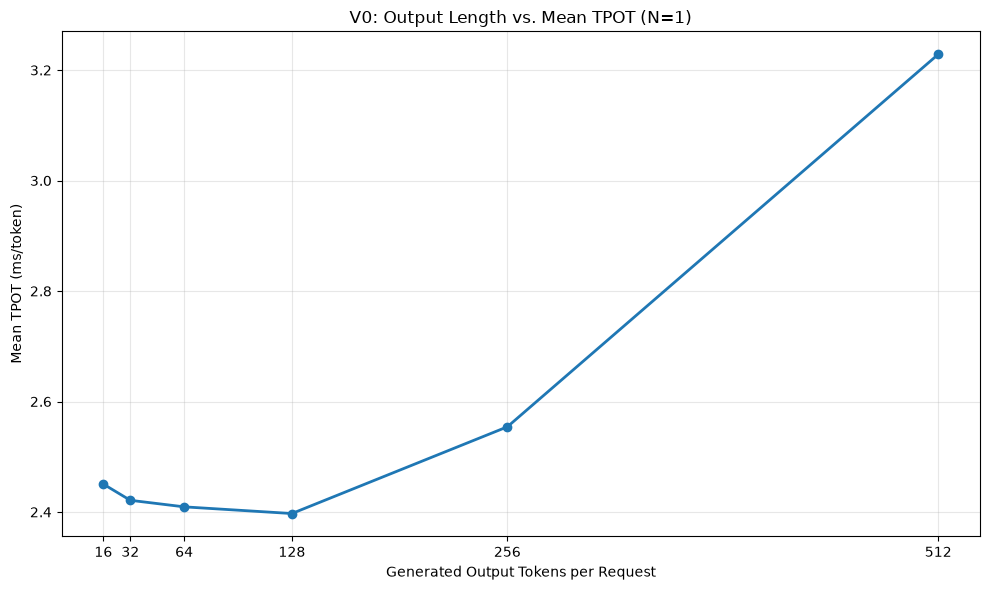

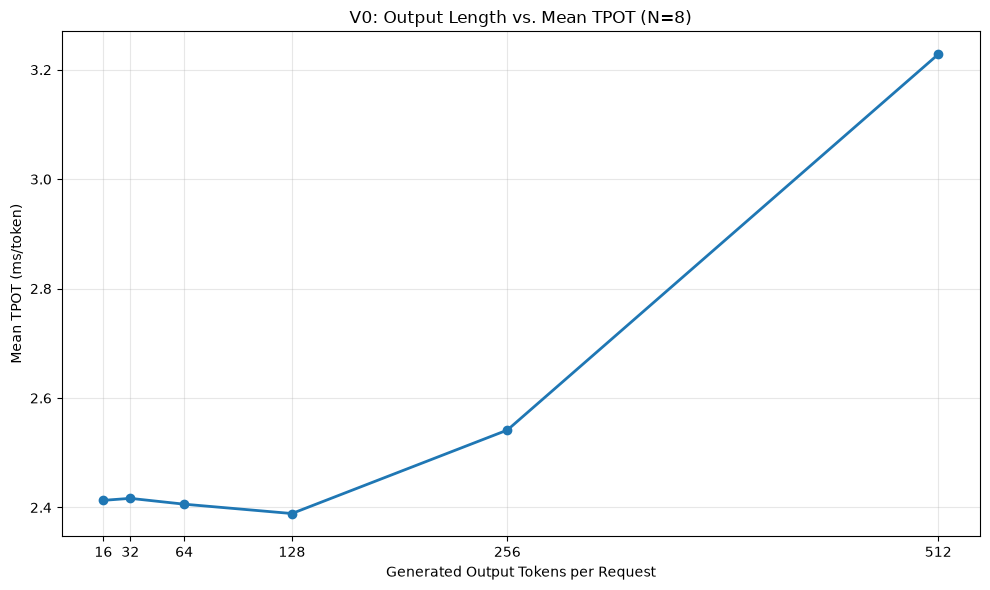

In [36]:
# Experiment 2: Output Scaling - Mean Time Per Output Token
e2 = df[
    (df["prompt_tokens"] == 64) &
    (df["num_requests"].isin([1, 8])) &
    (df["output_tokens"].isin([16, 32, 64, 128, 256, 512]))
]

# Median across 3 trials
e2 = e2.groupby(
    ["num_requests", "output_tokens"], as_index=False
)["mean_tpot_ms"].median()

# Generate separate graphs for N=1 and N=8
for n in [1, 8]:
    subset = e2[e2["num_requests"] == n]

    plt.figure(figsize=(10, 6))

    plt.plot(
        subset["output_tokens"],
        subset["mean_tpot_ms"],
        marker="o",
        linewidth=2,
        color="tab:blue"
    )

    plt.xticks([16, 32, 64, 128, 256, 512])

    plt.xlabel("Generated Output Tokens per Request")
    plt.ylabel("Mean TPOT (ms/token)")
    plt.title(f"V0: Output Length vs. Mean TPOT (N={n})")

    plt.grid(alpha=0.3)
    plt.tight_layout()

    plt.savefig(f"experiment2_tpot_{n}.png", dpi=300)
    plt.show()